In [1]:
# Run this cell before the panel cells.
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as PILImage

# Set BASE to the folder containing these notebooks.
BASE = Path.cwd()
DATA_DIR = BASE / "data"
# PROJECT_ROOT contains the map and segment inputs.
PROJECT_ROOT = Path(os.environ.get("TOMTOM_PROJECT_ROOT", str(BASE / "source_data")))
OUTPUT_ROOT = BASE / "figures" / "fig3"
USE_SAVED_MAPS = True

def show_saved(path):
    with PILImage.open(path) as image:
        image = image.convert("RGB")
        width, height = image.size
        fig, ax = plt.subplots(figsize=(9, 9 * height / width))
        ax.imshow(image)
        ax.axis("off")
        fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
        plt.show()
        plt.close(fig)


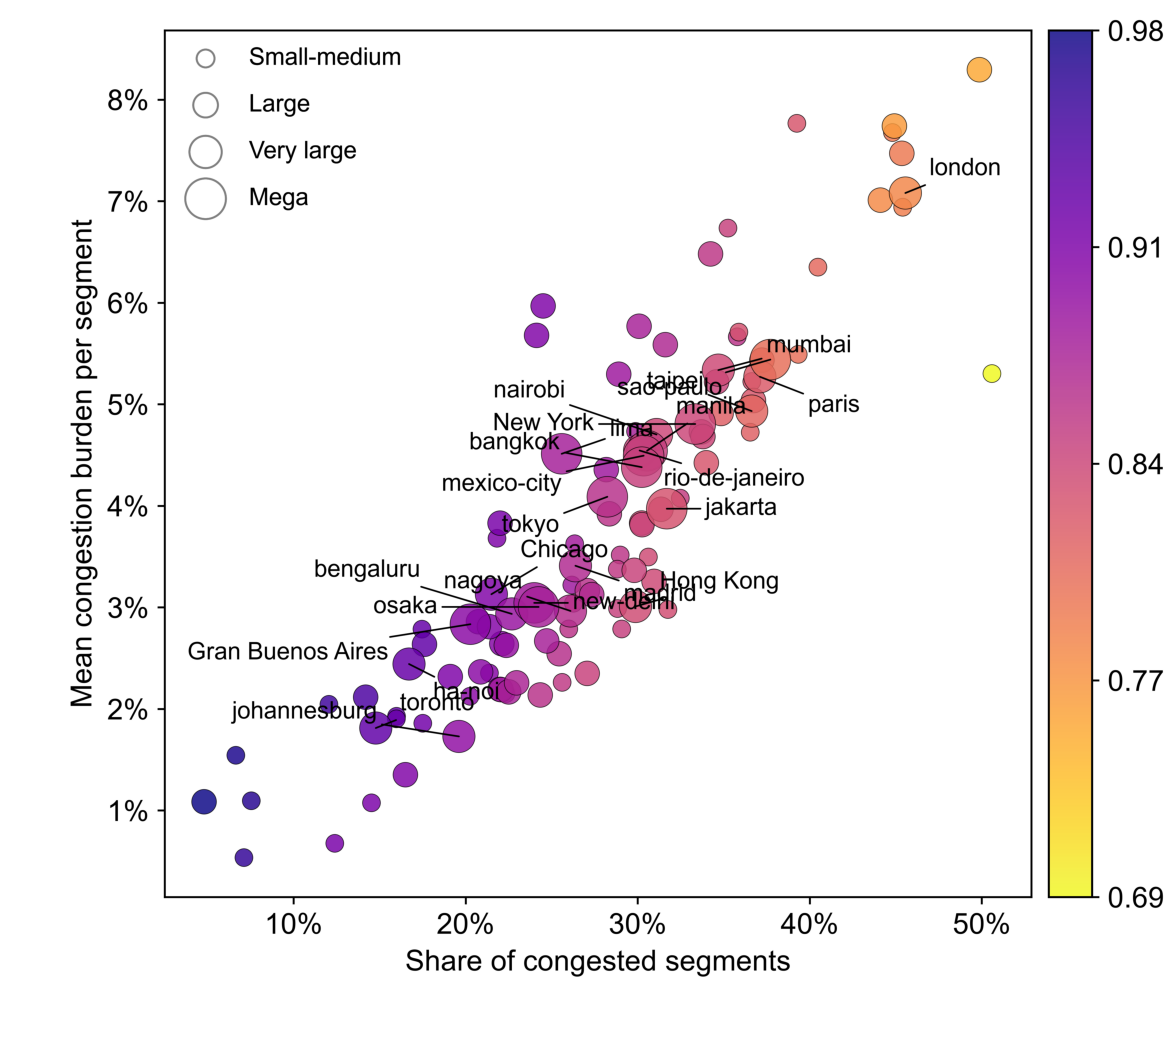

In [2]:
# Panel a: Bubble
def bubble(data_dir, project_root, output_dir):

    output_dir.mkdir(parents=True, exist_ok=True)
    import re
    import unicodedata
    import warnings
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    BY_CITY_ROOT = Path(str(project_root / 'GIS/segment_congestion_all_cities/by_city'))

    CITY_METRIC_CSV = Path(
        str(project_root / 'GIS/segment_congestion_all_cities/all_cities_aggregate/all_city_metrics.csv')
    )

    POP_CSV = Path(
        str(project_root / 'data/final_data/API_2025_full_year_city_summary_filtered_merged_with_time_shift_v2.csv')
    )

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG = 400

    AX_W = 5.0
    AX_H = 5.0

    LEFT_MARGIN = 0.95
    BOTTOM_MARGIN = 0.90
    TOP_MARGIN = 0.18

    RIGHT_GAP = 0.10
    CBAR_W = 0.25
    RIGHT_MARGIN = 0.45

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    CBAR_SIZE = 12
    ANNOT_FS = 10

    SPINE_LW = 0.8
    POINT_ALPHA = 0.84
    POINT_EDGE_LW = 0.28
    ARROW_LW = 0.7

    LABEL_GROUPS = {"very large", "mega"}
    FORCE_LABEL_CITIES = {"paris", "bangkok"}

    SIZE_MAP = {
        "small-medium": 55,
        "large": 105,
        "very large": 180,
        "mega": 285,
    }

    GROUP_ORDER = ["small-medium", "large", "very large", "mega"]
    GROUP_LABELS = {
        "small-medium": "Small-medium",
        "large": "Large",
        "very large": "Very large",
        "mega": "Mega",
    }

    LABEL_OFFSETS = [
        (10, 10), (10, -12), (-34, 10), (-34, -12),
        (12, 18), (-38, 18), (16, 0), (-42, 0),
        (20, 10), (-20, 12), (20, -12), (-20, -12)
    ]

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    CITY_ALIASES = {
        "gran buenos aires": "buenos aires",
        "lisboa": "lisbon",
        "sevilla": "seville",
        "taipei city": "taipei",
        "mexico city": "ciudad de mexico",
        "mexico-city": "ciudad de mexico",
        "sao paulo": "sao paulo",
        "ho chi minh city": "ho chi minh",
        "washington dc": "washington",
        "washington, dc": "washington",
        "new york city": "new york",
    }

    def strip_accents(text: str) -> str:
        text = unicodedata.normalize("NFKD", str(text))
        return "".join(ch for ch in text if not unicodedata.combining(ch))

    def normalize_city(text: str) -> str:
        if pd.isna(text):
            return ""
        text = str(text).strip()
        text = strip_accents(text)
        text = text.lower()
        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = text.replace("/", " ")
        text = text.replace(".", " ")
        text = re.sub(r"\(.*?\)", " ", text)
        if "," in text:
            text = text.split(",")[0].strip()
        text = re.sub(r"\s+", " ", text).strip()
        text = CITY_ALIASES.get(text, text)
        return text

    def classify_pop(pop):
        if pd.isna(pop):
            return np.nan
        if pop < 1_000_000:
            return "small-medium"
        elif pop < 5_000_000:
            return "large"
        elif pop < 10_000_000:
            return "very large"
        else:
            return "mega"

    def safe_read_csv(fp):
        try:
            return pd.read_csv(fp)
        except Exception as e:
            warnings.warn(f"Failed to read {fp}: {e}")
            return None

    def create_figure_with_fixed_main_axes_and_cbar(
        ax_w=5.0,
        ax_h=5.0,
        left=0.95,
        bottom=0.90,
        top=0.18,
        right_gap=0.10,
        cbar_w=0.38,
        right_margin=0.22,
        dpi=140
    ):

        fig_w = left + ax_w + right_gap + cbar_w + right_margin
        fig_h = bottom + ax_h + top

        fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)

        ax = fig.add_axes([
            left / fig_w,
            bottom / fig_h,
            ax_w / fig_w,
            ax_h / fig_h
        ])

        cax = fig.add_axes([
            (left + ax_w + right_gap) / fig_w,
            bottom / fig_h,
            cbar_w / fig_w,
            ax_h / fig_h
        ])

        return fig, ax, cax

    print("CITY_METRIC_CSV exists:", CITY_METRIC_CSV.exists(), CITY_METRIC_CSV)
    print("POP_CSV exists:", POP_CSV.exists(), POP_CSV)

    city_df = pd.read_csv(CITY_METRIC_CSV)
    pop_df = pd.read_csv(POP_CSV)

    if "ghsl_folder" not in city_df.columns:
        raise ValueError("all_city_metrics.csv missing 'ghsl_folder' column.")

    pop_cols_lower_map = {str(c).strip().lower(): c for c in pop_df.columns}
    if "city" not in pop_cols_lower_map:
        raise ValueError(f"Population file missing city column. Available columns: {pop_df.columns.tolist()}")
    if "pop" not in pop_cols_lower_map:
        raise ValueError(f"Population file missing pop column. Available columns: {pop_df.columns.tolist()}")

    CITY_COL = pop_cols_lower_map["city"]
    POP_COL = pop_cols_lower_map["pop"]

    city_df = city_df.copy()
    city_df["city_match_key"] = city_df["ghsl_folder"].apply(normalize_city)
    city_df["ghsl_city_raw"] = city_df["ghsl_folder"].astype(str).str.split(",").str[0].str.strip()

    pop_df = pop_df.copy()
    pop_df["city_match_key"] = pop_df[CITY_COL].apply(normalize_city)
    pop_df = pop_df.sort_values(["city_match_key", POP_COL], ascending=[True, False])
    pop_df_unique = pop_df.drop_duplicates(subset=["city_match_key"], keep="first").copy()

    merged = city_df.merge(
        pop_df_unique[[CITY_COL, "city_match_key", POP_COL]],
        on="city_match_key",
        how="left",
        suffixes=("", "_popsrc")
    )

    merged["city_src"] = merged[CITY_COL]
    merged["pop"] = merged[POP_COL]
    merged["pop_class"] = merged["pop"].apply(classify_pop)
    merged["pop_million"] = merged["pop"] / 1_000_000
    merged["folder_match_key"] = merged["ghsl_folder"].astype(str).str.strip().str.lower()

    city_dirs = sorted([p for p in BY_CITY_ROOT.iterdir() if p.is_dir()], key=lambda x: x.name.lower())

    rows = []

    print("=" * 110)
    print(f"Found city folders: {len(city_dirs)}")
    print("=" * 110)

    for city_dir in city_dirs:
        seg_fp = city_dir / "segment_metrics.csv"
        if not seg_fp.exists():
            warnings.warn(f"Missing segment_metrics.csv: {city_dir}")
            continue

        folder_name = city_dir.name.strip().lower()
        meta = merged.loc[merged["folder_match_key"] == folder_name].copy()

        if meta.empty:
            warnings.warn(f"No matched city metadata found for folder: {city_dir.name}")
            continue

        meta = meta.iloc[0]

        seg_df = safe_read_csv(seg_fp)
        if seg_df is None or seg_df.empty:
            continue

        if "peak_active_ratio" not in seg_df.columns:
            warnings.warn(f"'peak_active_ratio' not found in {seg_fp}")
            continue

        vals = pd.to_numeric(seg_df["peak_active_ratio"], errors="coerce").dropna()
        if vals.empty:
            continue

        city_name_raw = str(meta["ghsl_city_raw"]).strip()

        rows.append({
            "ghsl_folder": meta["ghsl_folder"],
            "city_name": city_name_raw,
            "city_name_lower": city_name_raw.lower(),
            "pop": meta["pop"],
            "pop_million": meta["pop_million"],
            "pop_class": meta["pop_class"],
            "gini": meta["peak_gini"],
            "congestion_extent": meta["peak_active_segment_share"],
            "mean_segment_burden": vals.mean(),
            "n_segments": len(vals)
        })

    plot_df = pd.DataFrame(rows)

    if plot_df.empty:
        raise ValueError("No valid city-level rows were built.")

    plot_df = plot_df.dropna(subset=[
        "pop", "pop_class", "gini",
        "congestion_extent", "mean_segment_burden"
    ]).copy()

    plot_df["bubble_size"] = plot_df["pop_class"].map(SIZE_MAP)
    plot_df = plot_df.sort_values("bubble_size", ascending=True).reset_index(drop=True)

    def draw_base_scatter(ax, cax, df):
        gini_min = float(df["gini"].min())
        gini_max = float(df["gini"].max())

        sc = ax.scatter(
            df["congestion_extent"],
            df["mean_segment_burden"],
            s=df["bubble_size"],
            c=df["gini"],
            cmap="plasma_r",
            vmin=gini_min,
            vmax=gini_max,
            alpha=POINT_ALPHA,
            edgecolors="black",
            linewidths=POINT_EDGE_LW,
            zorder=3
        )

        cbar = plt.colorbar(sc, cax=cax)
        cbar.set_label("Gini coefficient", fontsize=LABEL_SIZE)

        ticks = np.linspace(gini_min, gini_max, 5)
        cbar.set_ticks(ticks)
        cbar.set_ticklabels([f"{t:.2f}" for t in ticks])
        cbar.ax.tick_params(labelsize=CBAR_SIZE, length=3, width=0.8)

        ax.set_xlabel("Share of congested segments")
        ax.set_ylabel("Mean congestion burden per segment")

        ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        for spine in cax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        ax.grid(False)
        ax.tick_params(axis="both", length=3, width=0.8)

        return sc

    def add_size_legend(ax):
        legend_handles = [
            ax.scatter([], [], s=SIZE_MAP[g], facecolors="none", edgecolors="gray", linewidths=0.8)
            for g in GROUP_ORDER
        ]
        legend_labels = [GROUP_LABELS[g] for g in GROUP_ORDER]

        lg = ax.legend(
            legend_handles,
            legend_labels,
            loc="upper left",
            frameon=False,
            scatterpoints=1,
            labelspacing=1.0,
            handletextpad=0.8,
            borderpad=0.2,
            title=None,
            fontsize=LEGEND_SIZE
        )
        ax.add_artist(lg)

    def add_city_labels_with_lines(ax, df):
        label_df = df[
            df["pop_class"].isin(LABEL_GROUPS) | df["city_name_lower"].isin(FORCE_LABEL_CITIES)
        ].copy()

        label_df = label_df.sort_values(
            ["congestion_extent", "mean_segment_burden"]
        ).reset_index(drop=True)

        for i, (_, row) in enumerate(label_df.iterrows()):
            dx, dy = LABEL_OFFSETS[i % len(LABEL_OFFSETS)]
            ax.annotate(
                row["city_name"],
                xy=(row["congestion_extent"], row["mean_segment_burden"]),
                xytext=(dx, dy),
                textcoords="offset points",
                fontsize=ANNOT_FS,
                ha="left" if dx >= 0 else "right",
                va="center",
                arrowprops=dict(
                    arrowstyle="-",
                    color="black",
                    lw=ARROW_LW,
                    shrinkA=0,
                    shrinkB=0
                ),
                zorder=5
            )

    fig, ax, cax = create_figure_with_fixed_main_axes_and_cbar(
        ax_w=AX_W,
        ax_h=AX_H,
        left=LEFT_MARGIN,
        bottom=BOTTOM_MARGIN,
        top=TOP_MARGIN,
        right_gap=RIGHT_GAP,
        cbar_w=CBAR_W,
        right_margin=RIGHT_MARGIN,
        dpi=DPI_SHOW
    )

    draw_base_scatter(ax, cax, plot_df)
    add_size_legend(ax)

    fig.savefig(CODE_OUT_DIR / "fig_overall_bubble_city_gini_nocitylabels_mean.png", dpi=DPI_SAVE)
    fig.savefig(CODE_OUT_DIR / "fig_overall_bubble_city_gini_nocitylabels_mean.svg")
    fig.savefig(CODE_OUT_DIR / "fig_overall_bubble_city_gini_nocitylabels_mean.jpg", dpi=DPI_JPG, format="jpg")
    pass
    plt.close(fig)

    fig, ax, cax = create_figure_with_fixed_main_axes_and_cbar(
        ax_w=AX_W,
        ax_h=AX_H,
        left=LEFT_MARGIN,
        bottom=BOTTOM_MARGIN,
        top=TOP_MARGIN,
        right_gap=RIGHT_GAP,
        cbar_w=CBAR_W,
        right_margin=RIGHT_MARGIN,
        dpi=DPI_SHOW
    )

    draw_base_scatter(ax, cax, plot_df)
    add_size_legend(ax)
    add_city_labels_with_lines(ax, plot_df)

    fig.savefig(CODE_OUT_DIR / "fig_overall_bubble_city_gini_withcitylabels_mean.png", dpi=DPI_SAVE)
    fig.savefig(CODE_OUT_DIR / "fig_overall_bubble_city_gini_withcitylabels_mean.svg")
    fig.savefig(CODE_OUT_DIR / "fig_overall_bubble_city_gini_withcitylabels_mean.jpg", dpi=DPI_JPG, format="jpg")
    pass
    plt.close(fig)

    print("\nDone.")
    print(f"Outputs saved to:\n{CODE_OUT_DIR}")

output_dir = OUTPUT_ROOT / "a"
with plt.rc_context():
    bubble(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'fig_overall_bubble_city_gini_withcitylabels_mean.png')


Population classes: <1M, 1–5M, 5–10M, >=10M.


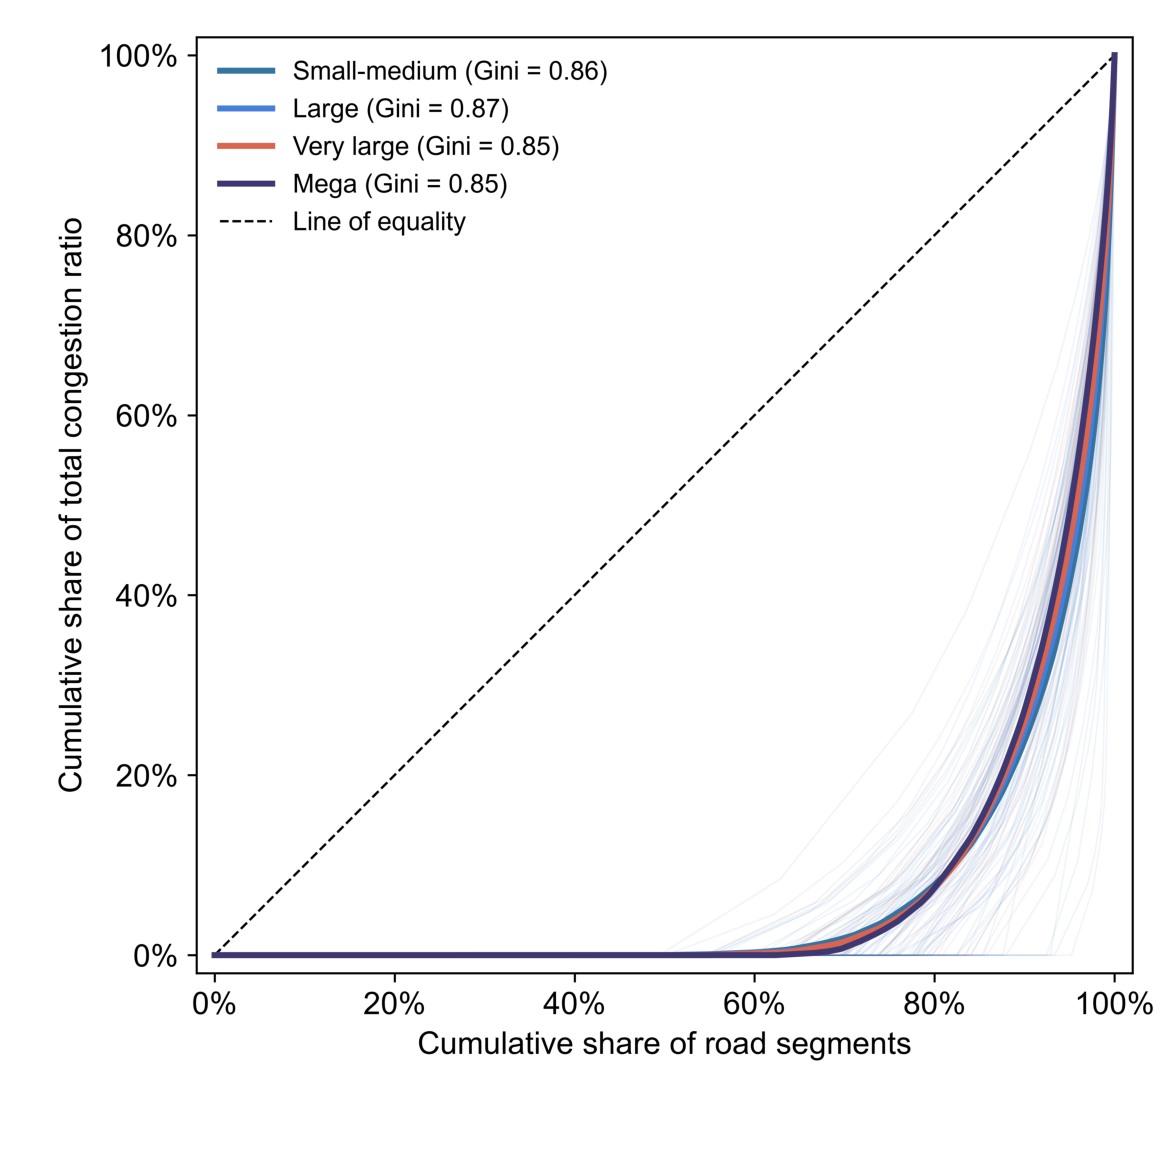

In [3]:
# Panel b: Lorenz
def lorenz(data_dir, project_root, output_dir):

    output_dir.mkdir(parents=True, exist_ok=True)
    import re
    import unicodedata
    import warnings
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    BY_CITY_ROOT = Path(str(project_root / 'GIS/segment_congestion_all_cities/by_city'))

    CITY_METRIC_CSV = Path(
        str(project_root / 'GIS/segment_congestion_all_cities/all_cities_aggregate/all_city_metrics.csv')
    )

    POP_CSV = Path(
        str(project_root / 'data/final_data/API_2025_full_year_city_summary_filtered_merged_with_time_shift_v2.csv')
    )

    OUT_DIR = output_dir
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG = 400

    AX_W = 5
    AX_H = 5

    LEFT_MARGIN   = 1.05
    RIGHT_MARGIN  = 0.20
    BOTTOM_MARGIN = 0.95
    TOP_MARGIN    = 0.20

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10

    LINEWIDTH_CITY = 0.55
    LINEWIDTH_GROUP = 2.3
    LINEWIDTH_EQUALITY = 0.9
    SPINE_WIDTH = 0.8

    ALPHA_CITY = 0.08

    N_GRID = 2000
    X_GRID = np.linspace(0, 1, N_GRID)

    GROUP_COLORS = {
        "small-medium": "#3573a1",
        "large": "#467fd9",
        "very large": "#d76552",
        "mega": "#3f3770",
    }
    GROUP_ORDER = ["small-medium", "large", "very large", "mega"]

    GROUP_LABELS = {
        "small-medium": "Small-medium",
        "large": "Large",
        "very large": "Very large",
        "mega": "Mega",
    }

    METRIC_CONFIGS = [{
            "metric_col": "peak_active_ratio",
            "metric_key": "peak",
            "out_stub": "fig1_lorenz_by_popclass_allpeak",
            "print_name": "all-peak",
        }]

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    CITY_ALIASES = {
        "gran buenos aires": "buenos aires",
        "lisboa": "lisbon",
        "sevilla": "seville",
        "taipei city": "taipei",
        "mexico city": "ciudad de mexico",
        "mexico-city": "ciudad de mexico",
        "sao paulo": "sao paulo",
        "ho chi minh city": "ho chi minh",
        "washington dc": "washington",
        "washington, dc": "washington",
        "new york city": "new york",
    }

    def strip_accents(text: str) -> str:
        text = unicodedata.normalize("NFKD", str(text))
        return "".join(ch for ch in text if not unicodedata.combining(ch))

    def normalize_city(text: str) -> str:
        if pd.isna(text):
            return ""
        text = str(text).strip()
        text = strip_accents(text)
        text = text.lower()

        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = text.replace("/", " ")
        text = text.replace(".", " ")

        text = re.sub(r"\(.*?\)", " ", text)

        if "," in text:
            text = text.split(",")[0].strip()

        text = re.sub(r"\s+", " ", text).strip()
        text = CITY_ALIASES.get(text, text)
        return text

    def safe_read_csv(fp):
        try:
            return pd.read_csv(fp)
        except Exception as e:
            warnings.warn(f"Failed to read {fp}: {e}")
            return None

    def lorenz_curve(values):
        x = np.asarray(values, dtype=float)
        x = x[np.isfinite(x)]
        x = x[x >= 0]

        if x.size == 0:
            return np.array([0.0, 1.0]), np.array([0.0, 1.0])

        x = np.sort(x)
        total = x.sum()

        if total == 0:
            n = len(x)
            return np.linspace(0, 1, n + 1), np.linspace(0, 1, n + 1)

        cumx = np.cumsum(x)
        y = np.insert(cumx / total, 0, 0.0)
        x_axis = np.linspace(0, 1, len(y))
        return x_axis, y

    def interpolate_curve(x, y, x_grid):
        return np.interp(x_grid, x, y)

    def gini_coefficient(x):
        x = np.asarray(x, dtype=np.float64)
        x = x[np.isfinite(x)]

        if x.size == 0:
            return np.nan
        if np.any(x < 0):
            raise ValueError("Negative values found.")

        total = x.sum()
        if total == 0:
            return 0.0

        x = np.sort(x)
        n = x.size
        i = np.arange(1, n + 1, dtype=np.float64)
        gini = (2.0 * np.dot(i, x)) / (n * total) - (n + 1.0) / n
        return float(max(0.0, min(1.0, gini)))

    def classify_pop(pop):
        if pd.isna(pop):
            return np.nan
        if pop < 1_000_000:
            return "small-medium"
        elif pop < 5_000_000:
            return "large"
        elif pop < 10_000_000:
            return "very large"
        else:
            return "mega"

    def create_figure_with_fixed_axes_box(
        ax_w=5.0,
        ax_h=5.0,
        left=1.0,
        right=0.2,
        bottom=0.9,
        top=0.2,
        dpi=140
    ):

        fig_w = left + ax_w + right
        fig_h = bottom + ax_h + top

        fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)
        ax = fig.add_axes([
            left / fig_w,
            bottom / fig_h,
            ax_w / fig_w,
            ax_h / fig_h
        ])
        return fig, ax

    print("CITY_METRIC_CSV exists:", CITY_METRIC_CSV.exists(), CITY_METRIC_CSV)
    print("POP_CSV exists:", POP_CSV.exists(), POP_CSV)

    city_df = pd.read_csv(CITY_METRIC_CSV)
    pop_df = pd.read_csv(POP_CSV)

    if "ghsl_folder" not in city_df.columns:
        raise ValueError("all_city_metrics.csv missing 'ghsl_folder' column.")

    pop_cols_lower_map = {str(c).strip().lower(): c for c in pop_df.columns}
    if "city" not in pop_cols_lower_map:
        raise ValueError(f"Population file missing city column. Available columns: {pop_df.columns.tolist()}")
    if "pop" not in pop_cols_lower_map:
        raise ValueError(f"Population file missing pop column. Available columns: {pop_df.columns.tolist()}")

    CITY_COL = pop_cols_lower_map["city"]
    POP_COL = pop_cols_lower_map["pop"]

    city_df = city_df.copy()
    city_df["city_match_key"] = city_df["ghsl_folder"].apply(normalize_city)
    city_df["ghsl_city_raw"] = city_df["ghsl_folder"].astype(str).str.split(",").str[0].str.strip()

    pop_df = pop_df.copy()
    pop_df["city_match_key"] = pop_df[CITY_COL].apply(normalize_city)
    pop_df = pop_df.sort_values(["city_match_key", POP_COL], ascending=[True, False])
    pop_df_unique = pop_df.drop_duplicates(subset=["city_match_key"], keep="first").copy()

    merged = city_df.merge(
        pop_df_unique[[CITY_COL, "city_match_key", POP_COL]],
        on="city_match_key",
        how="left",
        suffixes=("", "_popsrc")
    )

    merged["city_src"] = merged[CITY_COL]
    merged["pop"] = merged[POP_COL]
    merged["pop_class"] = merged["pop"].apply(classify_pop)
    merged["pop_million"] = merged["pop"] / 1_000_000
    merged["folder_match_key"] = merged["ghsl_folder"].astype(str).str.strip().str.lower()

    city_dirs = sorted([p for p in BY_CITY_ROOT.iterdir() if p.is_dir()], key=lambda x: x.name.lower())

    print("=" * 110)
    print(f"Found city folders: {len(city_dirs)}")
    print("=" * 110)

    for cfg in METRIC_CONFIGS:
        metric_col = cfg["metric_col"]
        metric_key = cfg["metric_key"]
        out_stub = cfg["out_stub"]
        print_name = cfg["print_name"]

        print("\n" + "#" * 120)
        print(f"PROCESSING LORENZ FIGURE FOR: {print_name}")
        print("#" * 120)

        group_curves = {g: [] for g in GROUP_ORDER}
        city_rows = []

        for city_dir in city_dirs:
            seg_fp = city_dir / "segment_metrics.csv"
            if not seg_fp.exists():
                warnings.warn(f"Missing segment_metrics.csv: {city_dir}")
                continue

            folder_name = city_dir.name.strip().lower()
            city_row = merged.loc[merged["folder_match_key"] == folder_name].copy()

            if city_row.empty:
                warnings.warn(f"No matched city metadata found for folder: {city_dir.name}")
                continue

            city_row = city_row.iloc[0]
            pop_class = city_row["pop_class"]
            pop_val = city_row["pop"]

            if pd.isna(pop_class):
                warnings.warn(f"City missing population class: {city_dir.name}")
                continue

            df = safe_read_csv(seg_fp)
            if df is None or df.empty:
                continue

            if metric_col not in df.columns:
                warnings.warn(f"'{metric_col}' not found in {seg_fp}")
                continue

            vals = pd.to_numeric(df[metric_col], errors="coerce")
            vals = vals[np.isfinite(vals) & (vals >= 0)].values
            if len(vals) == 0:
                continue

            x, y = lorenz_curve(vals)
            y_interp = interpolate_curve(x, y, X_GRID)
            gini = gini_coefficient(vals)

            group_curves[pop_class].append(y_interp)

            city_rows.append({
                "ghsl_folder": city_row["ghsl_folder"],
                "city_name": city_row["ghsl_city_raw"],
                "pop_class": pop_class,
                "pop_million": pop_val / 1_000_000 if pd.notna(pop_val) else np.nan,
                "n_segments": len(vals),
                f"{metric_key}_gini_recomputed": gini,
                "curve": y_interp
            })

        city_df_plot = pd.DataFrame(city_rows)

        if city_df_plot.empty:
            raise ValueError(f"No valid city-level Lorenz curves were built for {print_name}.")

        city_print_df = city_df_plot.drop(columns=["curve"]).copy()
        city_print_df = city_print_df.sort_values(
            ["pop_class", f"{metric_key}_gini_recomputed", "city_name"],
            ascending=[True, False, True]
        ).reset_index(drop=True)

        print("\n" + "=" * 110)
        print(f"City name + city size class + {print_name} Gini")
        print("=" * 110)
        print(
            city_print_df[["city_name", "pop_class", f"{metric_key}_gini_recomputed", "pop_million", "n_segments"]]
            .to_string(index=False)
        )

        summary_rows = []
        for g in GROUP_ORDER:
            sub = city_print_df[city_print_df["pop_class"] == g].copy()
            summary_rows.append({
                "pop_class": g,
                f"median_{metric_key}_gini": sub[f"{metric_key}_gini_recomputed"].median() if not sub.empty else np.nan,
                f"mean_{metric_key}_gini": sub[f"{metric_key}_gini_recomputed"].mean() if not sub.empty else np.nan,
                f"std_{metric_key}_gini": sub[f"{metric_key}_gini_recomputed"].std() if not sub.empty else np.nan,
                f"min_{metric_key}_gini": sub[f"{metric_key}_gini_recomputed"].min() if not sub.empty else np.nan,
                f"max_{metric_key}_gini": sub[f"{metric_key}_gini_recomputed"].max() if not sub.empty else np.nan,
            })

        summary_df = pd.DataFrame(summary_rows)

        print("\n" + "=" * 110)
        print(f"Group summary of {print_name} Gini")
        print("=" * 110)
        print(summary_df.to_string(index=False))

        city_print_df.to_csv(
            OUT_DIR / f"city_name_popclass_{metric_key}_gini_list.csv",
            index=False,
            encoding="utf-8-sig"
        )
        summary_df.to_csv(
            OUT_DIR / f"group_summary_{metric_key}_gini.csv",
            index=False,
            encoding="utf-8-sig"
        )

        group_mean_curves = {}
        group_median_ginis = {}

        for g in GROUP_ORDER:
            curves = group_curves[g]
            if len(curves) == 0:
                group_mean_curves[g] = None
                group_median_ginis[g] = np.nan
                continue

            curve_mat = np.vstack(curves)
            group_mean_curves[g] = np.mean(curve_mat, axis=0)

            sub = city_print_df[city_print_df["pop_class"] == g]
            group_median_ginis[g] = sub[f"{metric_key}_gini_recomputed"].median() if not sub.empty else np.nan

        fig, ax = create_figure_with_fixed_axes_box(
            ax_w=AX_W,
            ax_h=AX_H,
            left=LEFT_MARGIN,
            right=RIGHT_MARGIN,
            bottom=BOTTOM_MARGIN,
            top=TOP_MARGIN,
            dpi=DPI_SHOW
        )

        for _, row in city_df_plot.iterrows():
            ax.plot(
                X_GRID,
                row["curve"],
                color=GROUP_COLORS.get(row["pop_class"], "#666666"),
                linewidth=LINEWIDTH_CITY,
                alpha=ALPHA_CITY,
                zorder=1
            )

        for g in GROUP_ORDER:
            y = group_mean_curves[g]
            if y is None:
                continue

            label_txt = f"{GROUP_LABELS[g]} (Gini = {group_median_ginis[g]:.2f})"
            ax.plot(
                X_GRID,
                y,
                color=GROUP_COLORS.get(g, "#666666"),
                linewidth=LINEWIDTH_GROUP,
                alpha=1.0,
                label=label_txt,
                zorder=3
            )

        ax.plot(
            [0, 1], [0, 1],
            linestyle="--",
            linewidth=LINEWIDTH_EQUALITY,
            color="black",
            label="Line of equality",
            zorder=2
        )

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_WIDTH)

        ax.grid(False)
        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-0.02, 1.02)

        ax.set_xlabel("Cumulative share of road segments")
        ax.set_ylabel("Cumulative share of total congestion ratio")

        ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        ax.tick_params(axis="both", length=3.5, width=0.8)

        ax.legend(frameon=False, loc="upper left")

        fig.savefig(CODE_OUT_DIR / f"{out_stub}.png", dpi=DPI_SAVE)
        fig.savefig(CODE_OUT_DIR / f"{out_stub}.svg")
        fig.savefig(CODE_OUT_DIR / f"{out_stub}.jpg", dpi=DPI_JPG, format="jpg")

        pass
        plt.close(fig)

    print("\nDone.")
    print(f"Tables saved to:\n{OUT_DIR}")
    print(f"Figures saved to:\n{CODE_OUT_DIR}")

output_dir = OUTPUT_ROOT / "b"
with plt.rc_context():
    lorenz(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'fig1_lorenz_by_popclass_allpeak.png')


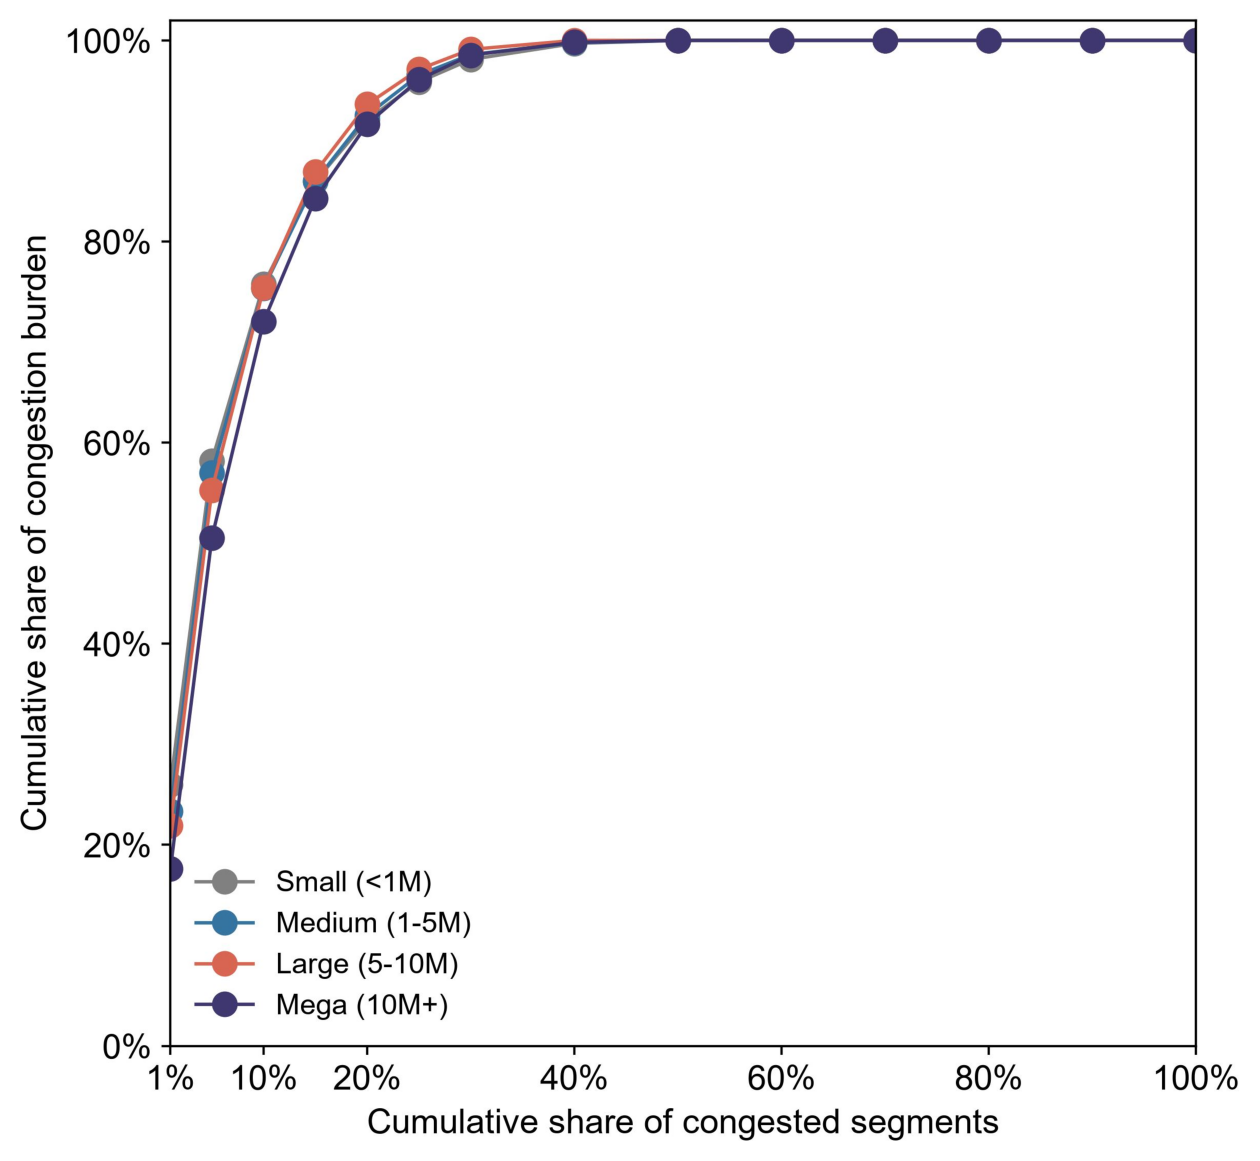

In [4]:
# Panel c: Capture
def capture(data_dir, project_root, output_dir):

    output_dir.mkdir(parents=True, exist_ok=True)
    import re
    import unicodedata
    import warnings
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    warnings.filterwarnings("ignore", category=RuntimeWarning)

    BY_CITY_ROOT = Path(str(project_root / 'GIS/segment_congestion_all_cities/by_city'))
    POP_FILE     = Path(str(project_root / 'data/final_data/API_2025_full_year_city_summary_filtered_merged_with_time_shift_v2.csv'))

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    BURDEN_COL = "peak_active_hours"
    USE_LENGTH_WEIGHTED = False

    DPI_SHOW = 140
    DPI_JPG  = 400

    AX_W = 5
    AX_H = 5

    LEFT_MARGIN   = 0.95
    RIGHT_MARGIN  = 0.30
    BOTTOM_MARGIN = 0.85
    TOP_MARGIN    = 0.25

    FONT_FAMILY = "Arial"
    TITLE_SIZE  = 12
    LABEL_SIZE  = 12
    TICK_SIZE   = 12
    LEGEND_SIZE = 10

    LINE_WIDTH = 1.2
    MARKER_SIZE = 8
    SPINE_LW = 0.8

    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }
    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]

    TOP_PCTS = np.array([1, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)

    MIN_VALID_SEGMENTS = 150
    MIN_POSITIVE_VALUES = 30

    PREFERRED_POP_COLS = [
        "UN_Pop_2025",
        "pop",
        "2020_urban_pop",
        "population",
        "Population",
    ]

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def create_figure_with_exact_axes_size(
        ax_w=5.0,
        ax_h=5.0,
        left_margin=0.95,
        right_margin=0.30,
        bottom_margin=0.85,
        top_margin=0.25,
        dpi=140
    ):
        fig_w = left_margin + ax_w + right_margin
        fig_h = bottom_margin + ax_h + top_margin

        fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)

        ax_left = left_margin / fig_w
        ax_bottom = bottom_margin / fig_h
        ax_width = ax_w / fig_w
        ax_height = ax_h / fig_h

        ax = fig.add_axes([ax_left, ax_bottom, ax_width, ax_height])
        return fig, ax

    def normalize_text(s):
        if pd.isna(s):
            return ""
        s = str(s).strip().lower()
        s = unicodedata.normalize("NFKD", s)
        s = "".join(ch for ch in s if not unicodedata.combining(ch))
        s = s.replace("&", "and")
        s = s.replace("_", " ")
        s = s.replace("-", " ")
        s = re.sub(r"[^\w\s]", " ", s)
        s = re.sub(r"\s+", " ", s).strip()
        return s

    def split_folder_city_country(folder_name):
        s = str(folder_name).strip()
        if "," in s:
            city_part, country_part = s.split(",", 1)
            return city_part.strip(), country_part.strip()
        return s.strip(), ""

    def classify_city_size(pop):
        if pd.isna(pop) or pop <= 0:
            return np.nan
        if pop < 1_000_000:
            return "Small (<1M)"
        elif pop < 5_000_000:
            return "Medium (1-5M)"
        elif pop < 10_000_000:
            return "Large (5-10M)"
        else:
            return "Mega (10M+)"

    def find_pop_col(df):
        cols_lower = {c.lower(): c for c in df.columns}
        for target in PREFERRED_POP_COLS:
            if target.lower() in cols_lower:
                return cols_lower[target.lower()]
        for c in df.columns:
            if "pop" in c.lower():
                return c
        return None

    def find_city_col(df):
        for c in df.columns:
            if c.lower() == "city":
                return c
        for c in df.columns:
            if "city" in c.lower():
                return c
        return None

    def find_country_col(df):
        for c in df.columns:
            if c.lower() == "country":
                return c
        for c in df.columns:
            if "country" in c.lower():
                return c
        return None

    def load_population_table(pop_file):
        pop_df = pd.read_csv(pop_file)

        city_col = find_city_col(pop_df)
        if city_col is None:
            raise ValueError("Population file missing city column.")

        pop_col = find_pop_col(pop_df)
        if pop_col is None:
            raise ValueError("Population file missing population column.")

        country_col = find_country_col(pop_df)

        out = pop_df.copy()
        out["city_raw"] = out[city_col].astype(str).str.strip()
        out["city_norm"] = out["city_raw"].map(normalize_text)
        out["population"] = pd.to_numeric(out[pop_col], errors="coerce")

        if country_col is not None:
            out["country_raw"] = out[country_col].astype(str).str.strip()
            out["country_norm"] = out["country_raw"].map(normalize_text)
        else:
            out["country_raw"] = ""
            out["country_norm"] = ""

        out = out.sort_values("population", ascending=False)
        out_city_country = out.drop_duplicates(subset=["city_norm", "country_norm"], keep="first").copy()
        out_city_only = out.drop_duplicates(subset=["city_norm"], keep="first").copy()
        return out_city_country, out_city_only

    def compute_top_capture_curve(x, top_pcts):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        x = x[x >= 0]
        if x.size == 0:
            return None

        xs = np.sort(x)[::-1]
        total = xs.sum()
        if total <= 0:
            return None

        n = len(xs)
        out = []
        for pct in top_pcts:
            k = int(np.ceil(n * pct / 100.0))
            k = max(1, min(k, n))
            capture = xs[:k].sum() / total
            out.append({"top_pct": pct, "capture_share": capture})
        return pd.DataFrame(out)

    pop_lookup_cc, pop_lookup_city = load_population_table(POP_FILE)

    city_files = sorted(BY_CITY_ROOT.rglob("segment_metrics.csv"))
    if len(city_files) == 0:
        raise FileNotFoundError(f"No segment_metrics.csv found under: {BY_CITY_ROOT}")

    capture_rows = []

    for i, fp in enumerate(city_files, start=1):
        print(f"[{i}/{len(city_files)}] {fp.parent.name}")

        try:
            df = pd.read_csv(fp)
        except Exception as e:
            print(f"  -> skip unreadable: {e}")
            continue

        if BURDEN_COL not in df.columns:
            print(f"  -> skip missing {BURDEN_COL}")
            continue

        folder_name = fp.parent.name
        city_part, country_part = split_folder_city_country(folder_name)
        city_norm = normalize_text(city_part)
        country_norm = normalize_text(country_part)

        x = pd.to_numeric(df[BURDEN_COL], errors="coerce").values.astype(float)

        if USE_LENGTH_WEIGHTED:
            if "length_m" not in df.columns:
                print("  -> skip missing length_m for weighted mode")
                continue
            length_m = pd.to_numeric(df["length_m"], errors="coerce").values.astype(float)
            x = x * length_m

        x = x[np.isfinite(x)]
        x = x[x >= 0]

        if len(x) < MIN_VALID_SEGMENTS:
            continue

        x_pos = x[x > 0]
        if len(x_pos) < MIN_POSITIVE_VALUES:
            continue

        row_match = pop_lookup_cc[
            (pop_lookup_cc["city_norm"] == city_norm) &
            (pop_lookup_cc["country_norm"] == country_norm)
        ]
        if len(row_match) == 0:
            row_match = pop_lookup_city[pop_lookup_city["city_norm"] == city_norm]

        population = row_match["population"].iloc[0] if len(row_match) > 0 else np.nan
        city_group = classify_city_size(population)

        if not isinstance(city_group, str):
            continue

        cap_df = compute_top_capture_curve(x, TOP_PCTS)
        if cap_df is not None:
            cap_df["city"] = folder_name
            cap_df["city_size_group"] = city_group
            capture_rows.append(cap_df)

    if len(capture_rows) == 0:
        raise ValueError("No usable capture-curve results generated.")

    capture_all = pd.concat(capture_rows, ignore_index=True)

    capture_group = (
        capture_all.groupby(["city_size_group", "top_pct"], as_index=False)
                   .agg(capture_share=("capture_share", "mean"))
    )

    capture_group["group_order"] = capture_group["city_size_group"].map(
        {g: i for i, g in enumerate(GROUP_ORDER)}
    )
    capture_group = capture_group.sort_values(["group_order", "top_pct"]).drop(columns="group_order")

    print("\n" + "=" * 100)
    print("Captured share of total peak burden by city size group")
    print("=" * 100)

    capture_print = capture_group.copy()
    capture_print["top_pct_label"] = capture_print["top_pct"].astype(int).astype(str) + "%"
    capture_print["capture_share_pct"] = capture_print["capture_share"] * 100

    capture_wide = (
        capture_print.pivot(index="top_pct_label", columns="city_size_group", values="capture_share_pct")
        .reindex([f"{int(x)}%" for x in TOP_PCTS])
    )

    capture_wide = capture_wide.round(2)

    print(capture_wide.to_string())

    focus_rows = ["1%", "10%", "20%", "40%", "60%", "80%", "100%"]
    print("\n" + "=" * 100)
    print("Focused percentages (1%, 5%, 10%, 20%)")
    print("=" * 100)
    print(capture_wide.loc[focus_rows].to_string())

    fig, ax = create_figure_with_exact_axes_size(
        ax_w=AX_W,
        ax_h=AX_H,
        left_margin=LEFT_MARGIN,
        right_margin=RIGHT_MARGIN,
        bottom_margin=BOTTOM_MARGIN,
        top_margin=TOP_MARGIN,
        dpi=DPI_SHOW
    )

    for grp in GROUP_ORDER:
        sub = capture_group[capture_group["city_size_group"] == grp].sort_values("top_pct")
        if sub.empty:
            continue
        ax.plot(
            sub["top_pct"],
            sub["capture_share"],
            lw=LINE_WIDTH,
            marker="o",
            markersize=MARKER_SIZE,
            color=GROUP_COLORS.get(grp, None),
            label=grp
        )

    ax.set_xlabel("Cumulative share of congested segments")
    ax.set_ylabel("Cumulative share of congestion burden")
    ax.set_xlim(1, 100)
    ax.set_ylim(0, 1.02)

    ax.set_xticks([1, 10, 20, 40, 60, 80, 100])
    ax.set_xticklabels(["1%", "10%", "20%", "40%", "60%", "80%", "100%"])

    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(SPINE_LW)

    ax.grid(False)
    ax.tick_params(axis="both", length=3, width=0.8)
    ax.legend(frameon=False, loc="best")

    fig.savefig(
        CODE_OUT_DIR / "FigD_top_segment_capture_5x5_400dpi.jpg",
        dpi=DPI_JPG,
        bbox_inches="tight",
        format="jpg"
    )

    pass
    plt.close(fig)

    print("\nDone.")
    print(f"Figure saved to:\n{CODE_OUT_DIR}")

output_dir = OUTPUT_ROOT / "c"
with plt.rc_context():
    capture(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'FigD_top_segment_capture_5x5_400dpi.jpg')


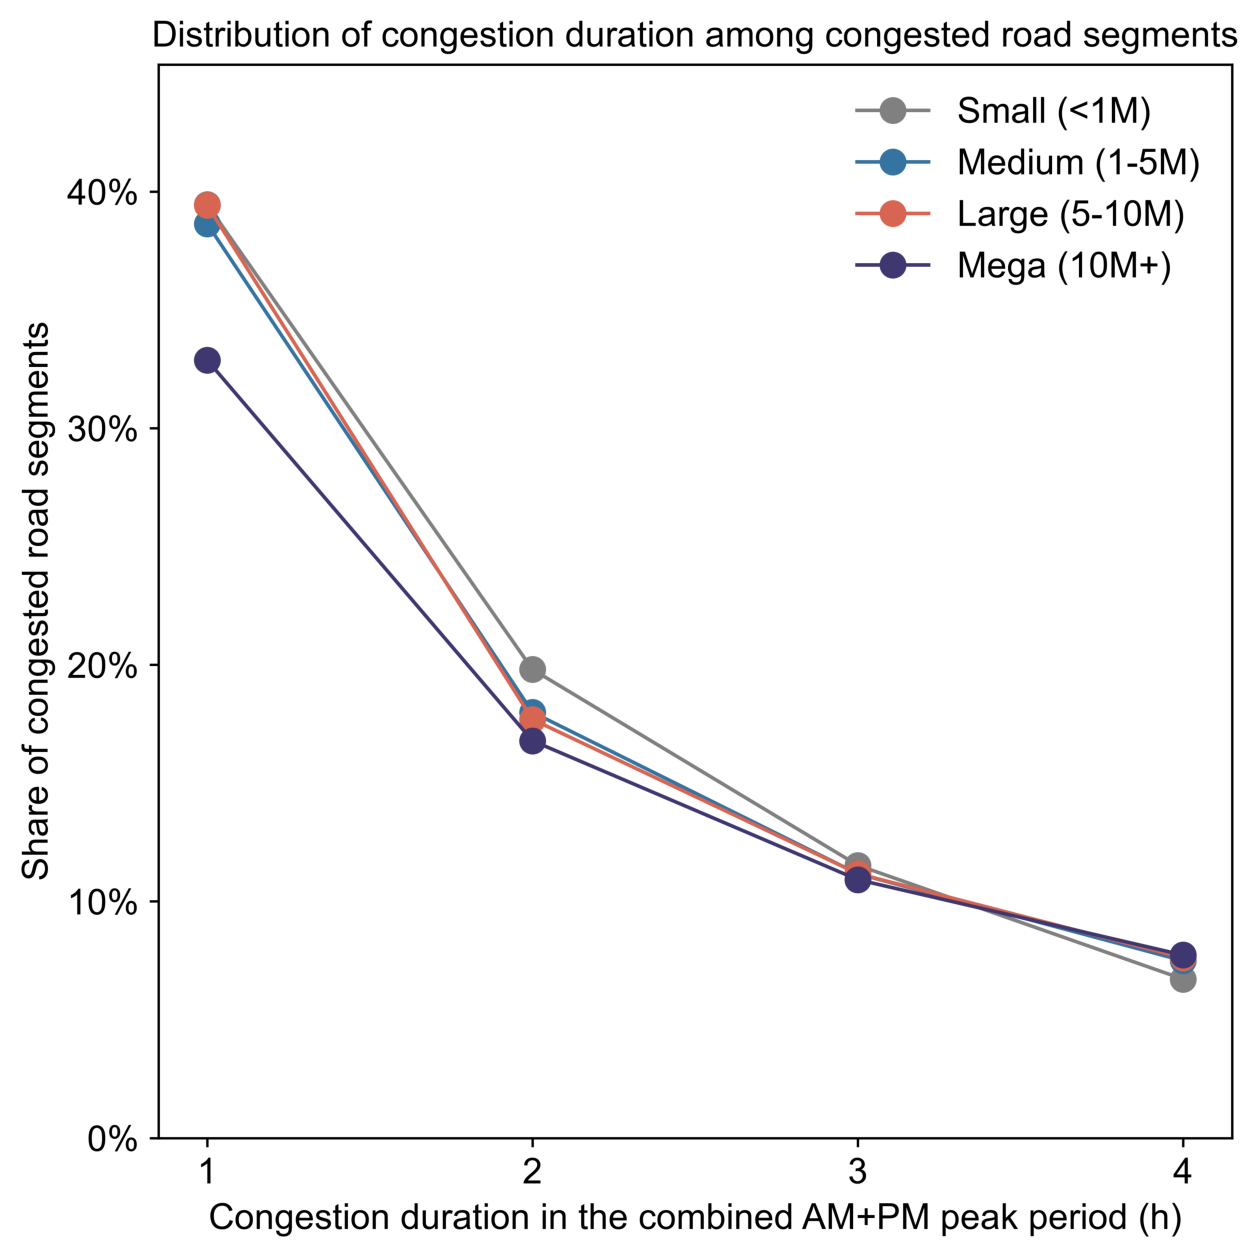

In [5]:
# Panel d: Duration
def duration(data_dir, project_root, output_dir):

    output_dir.mkdir(parents=True, exist_ok=True)
    import re
    import unicodedata
    import warnings
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    warnings.filterwarnings("ignore", category=RuntimeWarning)

    BY_CITY_ROOT = Path(str(project_root / 'GIS/segment_congestion_all_cities/by_city'))
    POP_FILE = Path(str(project_root / 'data/final_data/API_2025_full_year_city_summary_filtered_merged_with_time_shift_v2.csv'))

    OUT_DIR = output_dir
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    BURDEN_COL = "peak_active_hours"

    MIN_TOTAL_SEGMENTS = 150
    MIN_CONGESTED_SEGMENTS = 30

    DURATION_CATS = [1, 2, 3, 4]

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG = 400

    AX_W = 5
    AX_H = 5

    LEFT_MARGIN = 0.95
    RIGHT_MARGIN = 0.30
    BOTTOM_MARGIN = 0.85
    TOP_MARGIN = 0.25

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 12

    LINE_WIDTH = 1.2
    MARKER_SIZE = 8
    SPINE_LW = 0.8

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    PREFERRED_POP_COLS = [
        "UN_Pop_2025",
        "pop",
        "2020_urban_pop",
        "population",
        "Population",
    ]

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def create_figure_with_exact_axes_size(
        ax_w=5.0,
        ax_h=5.0,
        left_margin=0.95,
        right_margin=0.30,
        bottom_margin=0.85,
        top_margin=0.25,
        dpi=140
    ):
        fig_w = left_margin + ax_w + right_margin
        fig_h = bottom_margin + ax_h + top_margin

        fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)

        ax_left = left_margin / fig_w
        ax_bottom = bottom_margin / fig_h
        ax_width = ax_w / fig_w
        ax_height = ax_h / fig_h

        ax = fig.add_axes([ax_left, ax_bottom, ax_width, ax_height])
        return fig, ax

    def normalize_text(s):
        if pd.isna(s):
            return ""
        s = str(s).strip().lower()
        s = unicodedata.normalize("NFKD", s)
        s = "".join(ch for ch in s if not unicodedata.combining(ch))
        s = s.replace("&", "and")
        s = s.replace("_", " ")
        s = s.replace("-", " ")
        s = re.sub(r"[^\w\s]", " ", s)
        s = re.sub(r"\s+", " ", s).strip()
        return s

    def split_folder_city_country(folder_name):
        s = str(folder_name).strip()
        if "," in s:
            city_part, country_part = s.split(",", 1)
            return city_part.strip(), country_part.strip()
        return s.strip(), ""

    def classify_city_size(pop):
        if pd.isna(pop) or pop <= 0:
            return np.nan
        if pop < 1_000_000:
            return "Small (<1M)"
        elif pop < 5_000_000:
            return "Medium (1-5M)"
        elif pop < 10_000_000:
            return "Large (5-10M)"
        else:
            return "Mega (10M+)"

    def find_pop_col(df):
        cols_lower = {c.lower(): c for c in df.columns}
        for target in PREFERRED_POP_COLS:
            if target.lower() in cols_lower:
                return cols_lower[target.lower()]
        for c in df.columns:
            if "pop" in c.lower():
                return c
        return None

    def find_city_col(df):
        for c in df.columns:
            if c.lower() == "city":
                return c
        for c in df.columns:
            if "city" in c.lower():
                return c
        return None

    def find_country_col(df):
        for c in df.columns:
            if c.lower() == "country":
                return c
        for c in df.columns:
            if "country" in c.lower():
                return c
        return None

    def load_population_table(pop_file):
        pop_df = pd.read_csv(pop_file)

        city_col = find_city_col(pop_df)
        if city_col is None:
            raise ValueError("Population file missing city column.")

        pop_col = find_pop_col(pop_df)
        if pop_col is None:
            raise ValueError("Population file missing population column.")

        country_col = find_country_col(pop_df)

        out = pop_df.copy()
        out["city_raw"] = out[city_col].astype(str).str.strip()
        out["city_norm"] = out["city_raw"].map(normalize_text)
        out["population"] = pd.to_numeric(out[pop_col], errors="coerce")

        if country_col is not None:
            out["country_raw"] = out[country_col].astype(str).str.strip()
            out["country_norm"] = out["country_raw"].map(normalize_text)
        else:
            out["country_raw"] = ""
            out["country_norm"] = ""

        out = out.sort_values("population", ascending=False)
        out_city_country = out.drop_duplicates(subset=["city_norm", "country_norm"], keep="first").copy()
        out_city_only = out.drop_duplicates(subset=["city_norm"], keep="first").copy()
        return out_city_country, out_city_only

    pop_lookup_cc, pop_lookup_city = load_population_table(POP_FILE)

    city_files = sorted(BY_CITY_ROOT.rglob("segment_metrics.csv"))
    if len(city_files) == 0:
        raise FileNotFoundError(f"No segment_metrics.csv found under: {BY_CITY_ROOT}")

    rows = []

    for i, fp in enumerate(city_files, start=1):
        print(f"[{i}/{len(city_files)}] {fp.parent.name}")

        try:
            df = pd.read_csv(fp)
        except Exception as e:
            print(f"  -> skip unreadable: {e}")
            continue

        if BURDEN_COL not in df.columns:
            print(f"  -> skip missing {BURDEN_COL}")
            continue

        x_all = pd.to_numeric(df[BURDEN_COL], errors="coerce").values.astype(float)
        x_all = x_all[np.isfinite(x_all)]
        x_all = x_all[x_all >= 0]

        if len(x_all) < MIN_TOTAL_SEGMENTS:
            print(f"  -> skip too few total segments: {len(x_all)}")
            continue

        x_congested = x_all[x_all > 0]

        if len(x_congested) < MIN_CONGESTED_SEGMENTS:
            print(f"  -> skip too few congested segments: {len(x_congested)}")
            continue

        folder_name = fp.parent.name
        city_part, country_part = split_folder_city_country(folder_name)
        city_norm = normalize_text(city_part)
        country_norm = normalize_text(country_part)

        row_match = pop_lookup_cc[
            (pop_lookup_cc["city_norm"] == city_norm) &
            (pop_lookup_cc["country_norm"] == country_norm)
        ]
        if len(row_match) == 0:
            row_match = pop_lookup_city[pop_lookup_city["city_norm"] == city_norm]

        population = row_match["population"].iloc[0] if len(row_match) > 0 else np.nan
        city_group = classify_city_size(population)

        if pd.isna(city_group):
            print("  -> skip missing city size group")
            continue

        row = {
            "city": folder_name,
            "population": population,
            "city_size_group": city_group,
            "n_total_segments": int(len(x_all)),
            "n_congested_segments": int(len(x_congested)),
        }

        for h in DURATION_CATS:
            row[f"share_eq_{h}"] = float(np.mean(x_congested == h))

        rows.append(row)

    city_df = pd.DataFrame(rows)
    if len(city_df) == 0:
        raise ValueError("No valid city-level duration results were built.")

    city_df.to_csv(
        OUT_DIR / "city_exact_duration_profile_am_pm_4h_congested_segments_only.csv",
        index=False,
        encoding="utf-8-sig"
    )

    city_df["share_sum"] = city_df[[f"share_eq_{h}" for h in DURATION_CATS]].sum(axis=1)

    plot_df = (
        city_df
        .groupby("city_size_group", as_index=False)
        .agg(
            share_eq_1=("share_eq_1", "median"),
            share_eq_2=("share_eq_2", "median"),
            share_eq_3=("share_eq_3", "median"),
            share_eq_4=("share_eq_4", "median"),
            n_cities=("city", "nunique"),
            median_n_congested_segments=("n_congested_segments", "median")
        )
    )

    plot_df["group_order"] = plot_df["city_size_group"].map({g: i for i, g in enumerate(GROUP_ORDER)})
    plot_df = plot_df.sort_values("group_order").drop(columns="group_order")

    plot_df.to_csv(
        OUT_DIR / "group_exact_duration_profile_am_pm_4h_congested_segments_only_summary.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nGroup median summary:")
    print(plot_df.to_string(index=False))

    value_cols = [f"share_eq_{h}" for h in DURATION_CATS]

    long_df = plot_df.melt(
        id_vars=["city_size_group", "n_cities", "median_n_congested_segments"],
        value_vars=value_cols,
        var_name="duration",
        value_name="share"
    )

    duration_map = {f"share_eq_{h}": str(h) for h in DURATION_CATS}
    long_df["duration"] = long_df["duration"].map(duration_map)

    fig, ax = create_figure_with_exact_axes_size(
        ax_w=AX_W,
        ax_h=AX_H,
        left_margin=LEFT_MARGIN,
        right_margin=RIGHT_MARGIN,
        bottom_margin=BOTTOM_MARGIN,
        top_margin=TOP_MARGIN,
        dpi=DPI_SHOW
    )

    x_order = [str(h) for h in DURATION_CATS]

    for grp in GROUP_ORDER:
        sub = long_df[long_df["city_size_group"] == grp].copy()
        if sub.empty:
            continue

        sub["duration"] = pd.Categorical(sub["duration"], categories=x_order, ordered=True)
        sub = sub.sort_values("duration")

        ax.plot(
            sub["duration"].astype(str),
            sub["share"],
            marker="o",
            markersize=MARKER_SIZE,
            linewidth=LINE_WIDTH,
            color=GROUP_COLORS.get(grp, None),
            label=grp
        )

    ax.set_ylabel("Share of congested road segments")
    ax.set_xlabel("Congestion duration in the combined AM+PM peak period (h)")
    ax.set_title("Distribution of congestion duration among congested road segments")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
    ax.set_ylim(0, min(1.02, max(long_df["share"]) * 1.15))

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(SPINE_LW)

    ax.grid(False)
    ax.tick_params(axis="both", length=3, width=0.8)
    ax.legend(frameon=False, loc="best")

    fig.savefig(
        OUT_DIR / "Fig4d_exact_duration_profile_am_pm_4h_congested_segments_only.png",
        dpi=DPI_SAVE,
        bbox_inches="tight"
    )
    fig.savefig(
        OUT_DIR / "Fig4d_exact_duration_profile_am_pm_4h_congested_segments_only.svg",
        bbox_inches="tight"
    )
    fig.savefig(
        CODE_OUT_DIR / "Fig4d_exact_duration_profile_am_pm_4h_congested_segments_only.jpg",
        dpi=DPI_JPG,
        bbox_inches="tight",
        format="jpg"
    )

    pass
    plt.close(fig)

    print("\nDone.")
    print(f"Outputs saved to:\n{OUT_DIR}")
    print(f"Additional JPG saved to:\n{CODE_OUT_DIR}")

output_dir = OUTPUT_ROOT / "d"
with plt.rc_context():
    duration(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'Fig4d_exact_duration_profile_am_pm_4h_congested_segments_only.png')
